# CB0494 Mini Project

# Outlines

- [1: Import Libraries](#1)
- [2: Load Data](#2)
    - [2.1: Explore Data](#2.1)
- [3: Data Cleaning](#3)
    - [3.1: Irrelevant Data](#3.1)
    - [3.2: Missing Data](#3.2)
    - [3.3: Duplicated Data](#3.3)
    - [3.4: Conversion of Categorical Data to Numerical Data](#3.4)
- [4: Calculation of Depreciation Rate](#4)
- [5: Overall Analysis of Cleaned Data](#5)
    - [5.1: Summary Statistics of Depreciation Rate](#5.1)
    - [5.2: Depreciation Rate Distribution Visuals](#5.2)
- [6: Analysis of Numerical & Categorical Data](#6)
    - [6.1: Numerical Data](#6.1)
      - [6.1a: Summary Statistics of Numerical Data](#6.1a)
      - [6.1b: Detecting Outliers of Numerical Data](#6.1b)
      - [6.1c: Correlation of Numerical Data](#6.1c)
      - [6.1d: Linear Regression Model to Predict Depreciation using Floor Area](#6.1d)
      - [6.1e: Linear Regression Model to Predict Depreciation based on Floor Area](#6.1e)
      - [6.1f: Depreciation Prediction based on Month](#6.1f)
    - [6.2: Categorical Data](#6.2)
      - [6.2a: Summary Statistics for Categorical Data](#6.2a)
      - [6.2b: Relationship between Town and Depreciation Price](#6.2b)
      - [6.2c: Relationship between Flat Type and Depreciation Price](#6.2c)
      - [6.2d: Relationship between Storey Range and Depreciation Price](#6.2d)
      - [6.2e: Relationship between Flat Model and Depreciation Price](#6.2e)
- [7: Final Analysis of Model](#6)
    - [7.1: Multi-Variate Regression](#7.1)
    - [7.2: Regression Models on Depreciation Price vs Predictor](#7.2)
- [8: Mathematical Model](#7)

# 1: Import Libraries

> NumPy : Library for Numeric Computations in Python  
> Pandas : Library for Data Acquisition and Preparation  
> Matplotlib : Low-level library for Data Visualization  
> Seaborn : Higher-level library for Data Visualization  

In [5]:
# Importing essential libraries
import pandas as pd
import numpy as np
import seaborn as sb
import matplotlib.pyplot as plt
sb.set() # Setting default Seaborn style for graphics

# Display settings for data exploration
pd.set_option('display.max_columns', None)  # Show all columns
pd.set_option('display.float_format', '{:.2f}'.format)  # Format floats to 2 decimals

# 2: Load Data

#### Import of Data

Dataset from data.gov.sg : "Resale Flat Price"  
Source: https://data.gov.sg/dataset/resale-flat-prices

The dataset is `resale_flat_prices_based_on_registration_date_from_jan_2017_onwards.csv`;  `read_csv` function from Pandas is used.

In [8]:
#Load the dataset
flat_data = pd.read_csv('resale_flat_prices_based_on_registration_date_from_jan_2017_onwards.csv')
flat_data

,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,resale_price
0,2017-01,ANG MO KIO,2 ROOM,406,ANG MO KIO AVE 10,10 TO 12,44.00,Improved,1979,61 years 04 months,232000.00
1,2017-01,ANG MO KIO,3 ROOM,108,ANG MO KIO AVE 4,01 TO 03,67.00,New Generation,1978,60 years 07 months,250000.00
2,2017-01,ANG MO KIO,3 ROOM,602,ANG MO KIO AVE 5,01 TO 03,67.00,New Generation,1980,62 years 05 months,262000.00
3,2017-01,ANG MO KIO,3 ROOM,465,ANG MO KIO AVE 10,04 TO 06,68.00,New Generation,1980,62 years 01 month,265000.00
4,2017-01,ANG MO KIO,3 ROOM,601,ANG MO KIO AVE 5,01 TO 03,67.00,New Generation,1980,62 years 05 months,265000.00
...,...,...,...,...,...,...,...,...,...,...,...
201405,2025-02,YISHUN,EXECUTIVE,360,YISHUN RING RD,01 TO 03,146.00,Maisonette,1988,62 years 06 months,850000.00
201406,2025-02,YISHUN,EXECUTIVE,643,YISHUN ST 61,01 TO 03,142.00,Apartment,1987,61 years 08 months,830000.00
201407,2025-02,YISHUN,EXECUTIVE,723,YISHUN ST 71,07 TO 09,146.00,Maisonette,1986,60 years 05 months,818888.00
201408,2025-02,YISHUN,EXECUTIVE,824,YISHUN ST 81,01 TO 03,145.00,Apartment,1987,61 years 10 months,868888.00


### Next, displaying last 515 rows of the dataset to:
- Ensure that the dataset has been loaded correctly and that the data at the end of the file appears as expected. 
    
- To confirm if the structure is consistent with the rest of the data - data integrity.
    
- Large dataset, sampling the last portion of the data in order to ensure that the values and data organization follow the same structure as the rest of the dataset. This can help identify any outliers or issues that might only appear toward the end.

In [10]:
flat_data.tail(515)

,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,resale_price
200895,2025-02,SERANGOON,EXECUTIVE,519,SERANGOON NTH AVE 4,04 TO 06,150.00,Maisonette,1992,66 years 09 months,1218000.00
200896,2025-02,TAMPINES,2 ROOM,499B,TAMPINES AVE 9,04 TO 06,46.00,Model A,2014,88 years 02 months,363000.00
200897,2025-02,TAMPINES,2 ROOM,524B,TAMPINES CTRL 7,04 TO 06,47.00,Model A,2015,89 years 08 months,419000.00
200898,2025-02,TAMPINES,2 ROOM,299A,TAMPINES ST 22,07 TO 09,45.00,Model A,2012,86 years 02 months,372000.00
200899,2025-02,TAMPINES,3 ROOM,890A,TAMPINES AVE 1,01 TO 03,69.00,Model A,2015,89 years 08 months,550000.00
...,...,...,...,...,...,...,...,...,...,...,...
201405,2025-02,YISHUN,EXECUTIVE,360,YISHUN RING RD,01 TO 03,146.00,Maisonette,1988,62 years 06 months,850000.00
201406,2025-02,YISHUN,EXECUTIVE,643,YISHUN ST 61,01 TO 03,142.00,Apartment,1987,61 years 08 months,830000.00
201407,2025-02,YISHUN,EXECUTIVE,723,YISHUN ST 71,07 TO 09,146.00,Maisonette,1986,60 years 05 months,818888.00
201408,2025-02,YISHUN,EXECUTIVE,824,YISHUN ST 81,01 TO 03,145.00,Apartment,1987,61 years 10 months,868888.00


## 2.1 Explore Data
### General information about the dataset

In [12]:
print("\nDataset Information:")
flat_data.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 201410 entries, 0 to 201409
Data columns (total 11 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   month                201410 non-null  object 
 1   town                 201410 non-null  object 
 2   flat_type            201410 non-null  object 
 3   block                201410 non-null  object 
 4   street_name          201410 non-null  object 
 5   storey_range         201410 non-null  object 
 6   floor_area_sqm       201410 non-null  float64
 7   flat_model           201410 non-null  object 
 8   lease_commence_date  201410 non-null  int64  
 9   remaining_lease      201410 non-null  object 
 10  resale_price         201410 non-null  float64
dtypes: float64(2), int64(1), object(8)
memory usage: 16.9+ MB


In [13]:
x = flat_data.shape # Shows the no. of columns and rows of the data
print("Number of rows:",x[0])
print("Number of columns:",x[1])

Number of rows: 201410
Number of columns: 11


#### Observations:
The dataset contains **201,410 entries and 11 columns**:
1. **Non-Null Count**: All columns have **201,410 non-null** values, indicating there are **no missing values** in the dataset.
2. **Data Types**:
Output: float64(2), int64(1), object(8) represents:
    - 2 columns (`floor_area_sqm` and `resale_price`) are of type `float64`, which is expected for numerical values.
    - 1 column (`lease_commence_date`) is of type `int64`, representing a year or date in an integer format.
    - 8 columns (`month`, `town`, `flat_type`, `block`, `street_name`, `storey_range`, `flat_model`, and `remaining_lease`) are of type `object`, suggesting these are categorical or textual data.    
3. **Memory Usage**: The dataset occupies approximately 16.9 MB in memory.

# 3: Data Cleaning

## 3.1: Irrelevant Data

In [17]:
# Drop irrelevant columns like `Street Name`, `Block`, and `Lease Commencement Date`
flat_data = flat_data.drop(columns=["street_name", "block", "lease_commence_date"])

#### To confirm irrelevant columns have been dropped, table is printed again

In [19]:
flat_data.head()

,month,town,flat_type,storey_range,floor_area_sqm,flat_model,remaining_lease,resale_price
0,2017-01,ANG MO KIO,2 ROOM,10 TO 12,44.00,Improved,61 years 04 months,232000.00
1,2017-01,ANG MO KIO,3 ROOM,01 TO 03,67.00,New Generation,60 years 07 months,250000.00
2,2017-01,ANG MO KIO,3 ROOM,01 TO 03,67.00,New Generation,62 years 05 months,262000.00
3,2017-01,ANG MO KIO,3 ROOM,04 TO 06,68.00,New Generation,62 years 01 month,265000.00
4,2017-01,ANG MO KIO,3 ROOM,01 TO 03,67.00,New Generation,62 years 05 months,265000.00


## 3.2: Missing Data

For a complete, thorough analysis to identify any issues across the entire dataset and ensure the data quality is consistent.

In [21]:
flat_data.isna().sum()

month              0
town               0
flat_type          0
storey_range       0
floor_area_sqm     0
flat_model         0
remaining_lease    0
resale_price       0
dtype: int64

Based on the above output, there are **no missing values** present in the dataset.

## 3.3 Duplicated Data

In [24]:
# Check no. of duplicated data there are in the set
flat_data.duplicated().sum()

703

In [25]:
# Print duplicated data
flat_data[flat_data.duplicated()]

,month,town,flat_type,storey_range,floor_area_sqm,flat_model,remaining_lease,resale_price
243,2017-01,BUKIT MERAH,4 ROOM,07 TO 09,81.00,Improved,57 years,470000.00
305,2017-01,CENTRAL AREA,3 ROOM,16 TO 18,68.00,Improved,61 years 02 months,470000.00
510,2017-01,JURONG EAST,4 ROOM,04 TO 06,101.00,Model A,80 years 09 months,470000.00
591,2017-01,JURONG WEST,4 ROOM,19 TO 21,92.00,Model A,92 years 03 months,470000.00
672,2017-01,PASIR RIS,4 ROOM,01 TO 03,105.00,Model A,78 years 10 months,368000.00
...,...,...,...,...,...,...,...,...
198780,2025-01,TAMPINES,4 ROOM,07 TO 09,93.00,Model A,94 years 10 months,750000.00
198781,2025-01,TAMPINES,4 ROOM,13 TO 15,93.00,Model A,94 years 10 months,790000.00
198837,2025-01,TAMPINES,5 ROOM,10 TO 12,113.00,Improved,94 years 10 months,920000.00
200178,2025-02,JURONG WEST,3 ROOM,04 TO 06,74.00,Model A,60 years 03 months,400000.00


Based on the above output, there are **703 duplicated rows** where all column values are identical to another row.
We do not want redundant rows in our dataset as it may affect our findings later, thus our next step will be to remove them.

In [27]:
# Drop all duplicates
flat_data = flat_data.drop_duplicates()

#### To confirm all duplicated data have been dropped:

In [29]:
# Verify duplicates no longer there
flat_data.duplicated().sum()

0

## 3.4 Conversion of Categorical Data to Numerical Data

- Since we will be looking at Month to analyze depreciation per year, it is important we take into consideration the months, instead of the Year, thus the removal of YYYY from the data is necessary.
- Remaining lease will also be used for numerical analysis by converting its data to just read the YEAR.
- Resale price will also be converted to numerical variable in order to conduct Depreciation Rate Calculation for our further analysis.

In [32]:
flat_data['month'] = pd.to_datetime(flat_data['month']).dt.month
flat_data['month'] = flat_data['month'].astype('int64')

In [33]:
flat_data['remaining_lease'] = flat_data['remaining_lease'].astype(str).str[:2].astype(int) # take the year of the remaining lease and treat it as a numerical variable

In [34]:
flat_data['resale_price'] = flat_data['resale_price'].astype('int64')

In [35]:
flat_data.dtypes

month                int64
town                object
flat_type           object
storey_range        object
floor_area_sqm     float64
flat_model          object
remaining_lease      int64
resale_price         int64
dtype: object

# 4: Calculation of Depreciation Rate

In [37]:
flat_data["depreciation_per_year"] = flat_data["resale_price"] / flat_data["remaining_lease"]

# Save the updated DataFrame to an Excel file
flat_data.to_excel("flat_data_with_depreciation.xlsx", index=False)

print("Dataset with 'depreciation_per_year' column has been saved to 'flat_data_with_depreciation.xlsx'.")

flat_data # to double check if the column has been added

Dataset with 'depreciation_per_year' column has been saved to 'flat_data_with_depreciation.xlsx'.


,month,town,flat_type,storey_range,floor_area_sqm,flat_model,remaining_lease,resale_price,depreciation_per_year
0,1,ANG MO KIO,2 ROOM,10 TO 12,44.00,Improved,61,232000,3803.28
1,1,ANG MO KIO,3 ROOM,01 TO 03,67.00,New Generation,60,250000,4166.67
2,1,ANG MO KIO,3 ROOM,01 TO 03,67.00,New Generation,62,262000,4225.81
3,1,ANG MO KIO,3 ROOM,04 TO 06,68.00,New Generation,62,265000,4274.19
4,1,ANG MO KIO,3 ROOM,01 TO 03,67.00,New Generation,62,265000,4274.19
...,...,...,...,...,...,...,...,...,...
201405,2,YISHUN,EXECUTIVE,01 TO 03,146.00,Maisonette,62,850000,13709.68
201406,2,YISHUN,EXECUTIVE,01 TO 03,142.00,Apartment,61,830000,13606.56
201407,2,YISHUN,EXECUTIVE,07 TO 09,146.00,Maisonette,60,818888,13648.13
201408,2,YISHUN,EXECUTIVE,01 TO 03,145.00,Apartment,61,868888,14244.07


In [38]:
## since month is now a numeric value (1 to 12), it needs to be grouped and calculate the avg depreciation per year to see patterns over time.
monthly_avg_depreciation = flat_data.groupby('month')['depreciation_per_year'].mean().reset_index()

In [39]:
print(flat_data.groupby('month')['depreciation_per_year'].mean())

month
1    7153.05
2    7180.20
3    6830.34
4    6951.87
5    6992.89
6    6890.44
7    6957.55
8    7025.14
9    7021.92
10   7015.21
11   7044.26
12   7115.93
Name: depreciation_per_year, dtype: float64


In [40]:
print(flat_data['month'].unique())

[ 1  2  3  4  5  6  7  8  9 10 11 12]


# 5: Overall Analysis of Cleaning

In [42]:
import plotly.offline as py
import plotly.graph_objs as go
from plotly import subplots

In [43]:
# Activate inline plotting in notebook
py.init_notebook_mode(connected = False)

## 5.1: Summary Statistics of Depreciation Rate

In [45]:
# Calculate Depreciation Rate Statistics
DepreciationRate = pd.DataFrame(flat_data["depreciation_per_year"])

# Quartiles and IQR
Q1 = DepreciationRate.quantile(0.25)  # 25th percentile
Q3 = DepreciationRate.quantile(0.75)  # 75th percentile
IQR = Q3 - Q1

# Count and Percentage of Outliers
outliers = (DepreciationRate < (Q1 - 1.5 * IQR)) | (DepreciationRate > (Q3 + 1.5 * IQR))
count = outliers.sum()
percentage_outlier = (count.iloc[0] / len(DepreciationRate)) * 100

# Summary Statistics
print("Minimum Rate:", "\t\t", np.percentile(DepreciationRate["depreciation_per_year"], 0))
percentiles = [25, 50, 75]
for i in percentiles:
    print(f"{i}th Percentile:", "\t", np.percentile(DepreciationRate["depreciation_per_year"], i))
print("Maximum Rate:", "\t\t", np.percentile(DepreciationRate["depreciation_per_year"], 100))
print("Price Skewness:", "\t\t", DepreciationRate["depreciation_per_year"].skew().round(3))
print("Number of Outliers:", "\t", round(percentage_outlier, 2), "%")

Minimum Rate: 		 1595.7446808510638
25th Percentile: 	 5254.237288135593
50th Percentile: 	 6562.5
75th Percentile: 	 8210.526315789473
Maximum Rate: 		 33361.70212765958
Price Skewness: 		 1.252
Number of Outliers: 	 3.15 %


## 5.2: Depreciation Rate Distribution Visuals

In [47]:
deprerate_obj = flat_data["depreciation_per_year"]

# Interactive Histogram for Depreciation Rate
trace = go.Histogram(histnorm = 'density', x = deprerate_obj)

layout1 = go.Layout(title = 'Depreciation Rate Distribution',
                    xaxis_title = "Depreciation Rate",
                    yaxis_title = "Count")

fig = go.Figure(layout = layout1, data = trace)
fig.show()

In [48]:
# Interactive Boxplot
trace2 = go.Box(x = deprerate_obj, showlegend = False, name = 'Depreciation Rate')
layout2 = go.Layout(title = 'Interactive Boxplot')
data = [trace2]
fig_2 = go.Figure(layout = layout2, data = trace2)
fig_2.show()

#### Observations: 
Histogram :
- The depreciation rate is right-skewed, with most values concentrated on the lower end (below 10k).
- There are some high-value outliers that extend beyond 30k.
- The highest frequency of depreciation rates appears to be around 2k to 5k, with a steep decline afterward.

Boxplot:
- The interquartile range (IQR) shows most depreciation rates falling within a narrower range.
- There are many extreme outliers beyond the upper whisker, confirming that a small subset of resale flats has significantly high depreciation rates.
- The median depreciation rate is somewhere between 4k to 6k.
- The upper fence is around 12.36k, meaning anything above that is classified as an outlier.
- There are data points even beyond 30k, which might warrant further investigation.

# 6: Analysis of Numerical & Categorical Data

In [51]:
# Check for categorical and numerical columns
categorical_columns = flat_data.select_dtypes(include=['object']).columns.tolist()
numerical_columns = flat_data.select_dtypes(include=['float64', 'int64']).columns.tolist()
print("\nCategorical Columns:", categorical_columns)
print("Numerical Columns:", numerical_columns)


Categorical Columns: ['town', 'flat_type', 'storey_range', 'flat_model']
Numerical Columns: ['month', 'floor_area_sqm', 'remaining_lease', 'resale_price', 'depreciation_per_year']


#### Observations of the variables are based on our own interpretations:

| Variable              | Observation                   |    
| ---------------------:| :---------------------------: |    
| month                 | Numerical Variable, YYYY-MM   |  
| town                  | Categorical Variable          |
| flat_type             | Categorical Variable          |     
| storey_range          | Categorical Variable          |  
| flat_model            | Categorical Variable          |     
| floor_area_sqm        | Numeric Variable              |  
| remaining_lease       | Numeric Variable              |    
| resale_price          | Numeric Variable              |     
| depreciation_rate     | Numeric Variable              |     
| depreciation_per_year | Numeric Variable              |       

## 6.1: Numerical Data

##### Resale Price as an Independent Variable:
- Resale price is directly proportional to depreciation per year, as the latter is calculated using resale price. This means that resale price isn’t an external factor affecting depreciation. it is already embedded in how depreciation is derived. Using resale price as a predictor might lead to a circular dependency because depreciation per year is partly defined by resale price, thus it will be removed from our analysis.\
##### Depreciation Rate, Circular Dependency:
- Depreciation rate is calculated using the same variables as depreciation per year.
- Including it could lead to misleading results because it artificially inflates the correlation or predictive power, as the two variables are mathematically related.

### 6.1a: Summary Statistics of Numerical Data

In [56]:
# Numerical Data
numericalData = pd.DataFrame(flat_data[['month', 'remaining_lease', 'floor_area_sqm', 'depreciation_per_year']]) # analysise the numerical data first
numericalData.head()

,month,remaining_lease,floor_area_sqm,depreciation_per_year
0,1,61,44.00,3803.28
1,1,60,67.00,4166.67
2,1,62,67.00,4225.81
3,1,62,68.00,4274.19
4,1,62,67.00,4274.19


In [57]:
numericalData.describe()

,month,remaining_lease,floor_area_sqm,depreciation_per_year
count,200707.00,200707.00,200707.00,200707.00
mean,6.55,73.96,96.97,7015.08
std,3.44,14.09,24.05,2436.91
min,1.00,40.00,31.00,1595.74
25%,4.00,62.00,82.00,5254.24
50%,7.00,74.00,93.00,6562.50
75%,9.00,88.00,112.00,8210.53
max,12.00,97.00,366.70,33361.70


### 6.1b: Detecting Outliers of Numerical Data

- Analyzes and visualizes outliers in numerical columns of a DataFrame.
- data (pd.DataFrame): The DataFrame containing the data.
- numerical_columns (list): A list of numerical column names to analyze.
- plot_type (str): The type of visualization to use - 'counts', 'percentages', or 'both'.

Returns:
        dict: A dictionary containing outliers, their counts, and percentages for each column.

No. of IQR outliers in 'month': 0
Percentage of outliers: 0.00%
-----------------------------------------------------------------
No. of IQR outliers in 'remaining_lease': 0
Percentage of outliers: 0.00%
-----------------------------------------------------------------
No. of IQR outliers in 'floor_area_sqm': 1146
Percentage of outliers: 0.57%
-----------------------------------------------------------------
No. of IQR outliers in 'depreciation_per_year': 6318
Percentage of outliers: 3.15%
-----------------------------------------------------------------


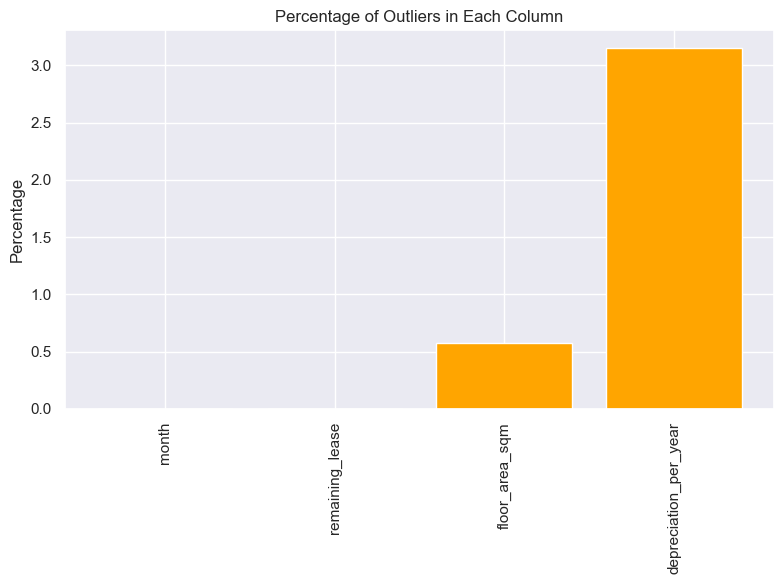

In [60]:
# Count outliers for each variable

def analyze_visualize_outliers(data, numericalData, plot_type="both"):

    # Dictionary to store outlier information for each column
    outlier_data = {}
    for col in numericalData:
        data_column = data[col]

        # Calculate Q1, Q3, IQR and bounds for outliers 
        Q1 = data_column.quantile(0.25)
        Q3 = data_column.quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        # Identify outliers based on the bounds
        outliers = data_column[(data_column < lower_bound) | (data_column > upper_bound)]
        outlier_counts = len(outliers)  # Count of outliers
        outlier_percentages = (outlier_counts / len(data_column)) * 100  # Percentage of outliers

        # Store the outlier data for the current column
        outlier_data[col] = {
            'count': outlier_counts,
            'percentage': outlier_percentages,
            'outliers': outliers.tolist()
        }

        # Print outliers 
        print(f"No. of IQR outliers in '{col}': {outlier_counts}")
        print(f"Percentage of outliers: {outlier_percentages:.2f}%")
        print("-----------------------------------------------------------------")

    # Visualization of outliers based on the specified plot type
    if plot_type == "counts":
        # Plot the number of outliers for each column
        fig, ax = plt.subplots(figsize=(8, 6))
        ax.bar(outlier_data.keys(), [v['count'] for v in outlier_data.values()], color='red')
        ax.set_title('Number of Outliers in Each Column')
        ax.set_ylabel('Count')
        ax.set_xticks(list(outlier_data.keys()))  # Set x-axis ticks
        ax.set_xticklabels(list(outlier_data.keys()), rotation=90)  # Rotate labels for readability
        plt.tight_layout()
        plt.show()

    elif plot_type == "percentages":
        # Plot the percentage of outliers for each column
        fig, ax = plt.subplots(figsize=(8, 6))
        ax.bar(outlier_data.keys(), [v['percentage'] for v in outlier_data.values()], color='orange')
        ax.set_title('Percentage of Outliers in Each Column')
        ax.set_ylabel('Percentage')
        ax.set_xticks(list(outlier_data.keys()))  # Set x-axis ticks
        ax.set_xticklabels(list(outlier_data.keys()), rotation=90)  # Rotate labels for readability
        plt.tight_layout()
        plt.show()

    elif plot_type == "both":
        # Plot both the count and percentage of outliers side by side
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

        # Plot outlier counts
        ax1.bar(outlier_data.keys(), [v['count'] for v in outlier_data.values()], color='red')
        ax1.set_title('Number of Outliers in Each Column')
        ax1.set_ylabel('Count')
        ax1.set_xticks(list(outlier_data.keys()))  # Set x-axis ticks
        ax1.set_xticklabels(list(outlier_data.keys()), rotation=90)  # Rotate labels for readability

        # Plot outlier percentages
        ax2.bar(outlier_data.keys(), [v['percentage'] for v in outlier_data.values()], color='orange')
        ax2.set_title('Percentage of Outliers in Each Column')
        ax2.set_ylabel('Percentage')
        ax2.set_xticks(list(outlier_data.keys()))  # Set x-axis ticks
        ax2.set_xticklabels(list(outlier_data.keys()), rotation=90)  # Rotate labels for readability

        plt.tight_layout()
        plt.show()

    else:
        # Handle invalid plot type
        print(f"Invalid plot_type: {plot_type}. Valid options are 'counts', 'percentages', or 'both'.")

    # Return the dictionary containing outlier information for further use
    return outlier_data

# Call the function to analyze and visualize outliers in numerical columns of the dataset
# Specify 'percentages' as the plot type to visualize the percentage of outliers in each column
outlier_results = analyze_visualize_outliers(flat_data, numericalData, plot_type="percentages")

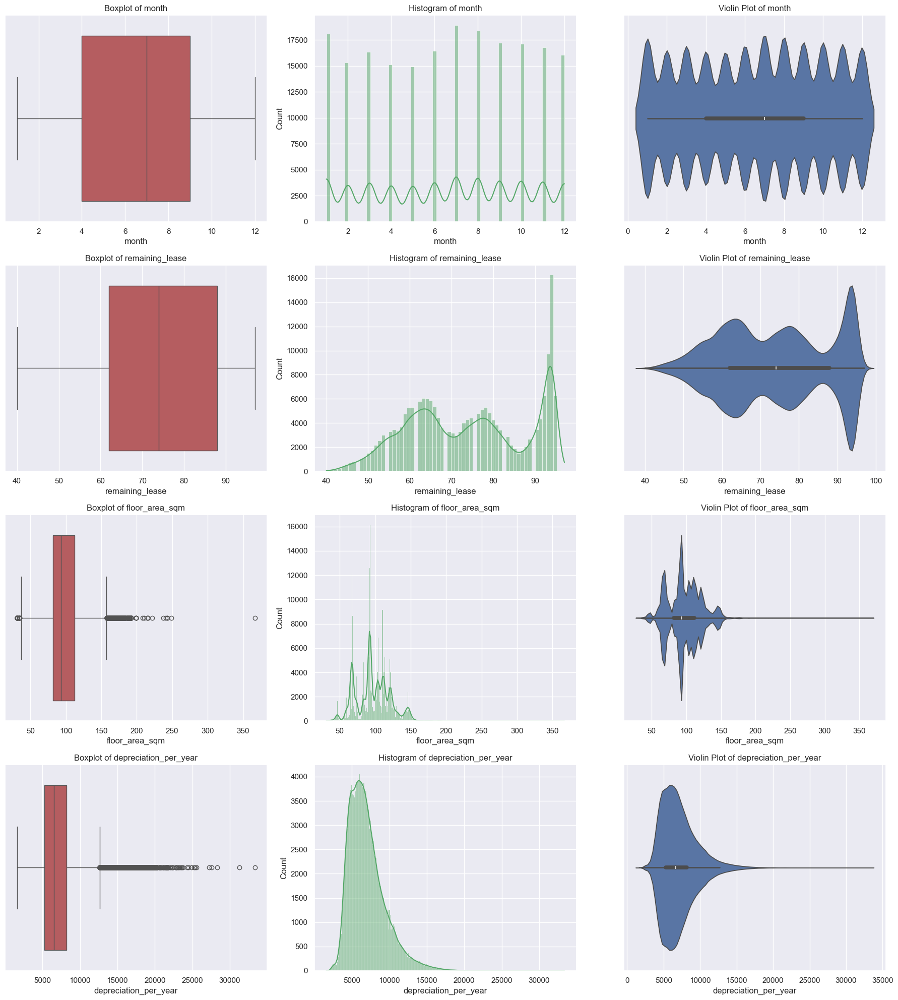

In [61]:
import math

# Determine the number of variables
num_vars = len(numericalData.columns)  # Total number of numerical variables
plots_per_var = 3  # Number of plots for each variable (boxplot, histogram, violinplot)
total_plots = num_vars * plots_per_var  # Total number of subplots required

# Calculate rows and columns for the subplot grid
cols = 3  # Number of plots per row
rows = math.ceil(total_plots / cols)  # Total number of rows needed

# Create the figure and axes grid
fig, axes = plt.subplots(rows, cols, figsize=(18, rows * 5))
axes = axes.flatten()  # Flatten the axes grid for easier indexing

colors = ["r", "g", "b"]  # Colors for plots

# Plot each variable
count = 0
for var in numericalData.columns:
    # Boxplot
    sb.boxplot(x=numericalData[var], color=colors[count % 3], ax=axes[count])
    axes[count].set_title(f"Boxplot of {var}")
    count += 1

    # Histogram
    sb.histplot(x=numericalData[var], kde=True, color=colors[count % 3], ax=axes[count])
    axes[count].set_title(f"Histogram of {var}")
    count += 1

    # Violin plot
    sb.violinplot(x=numericalData[var], color=colors[count % 3], ax=axes[count])
    axes[count].set_title(f"Violin Plot of {var}")
    count += 1

# Hide any unused subplot axes
for i in range(count, len(axes)):
    fig.delaxes(axes[i])  # Remove unused axes

# Adjust layout
plt.tight_layout()
plt.show()

### 6.1c: Correlation of Numerical Data

<Axes: >

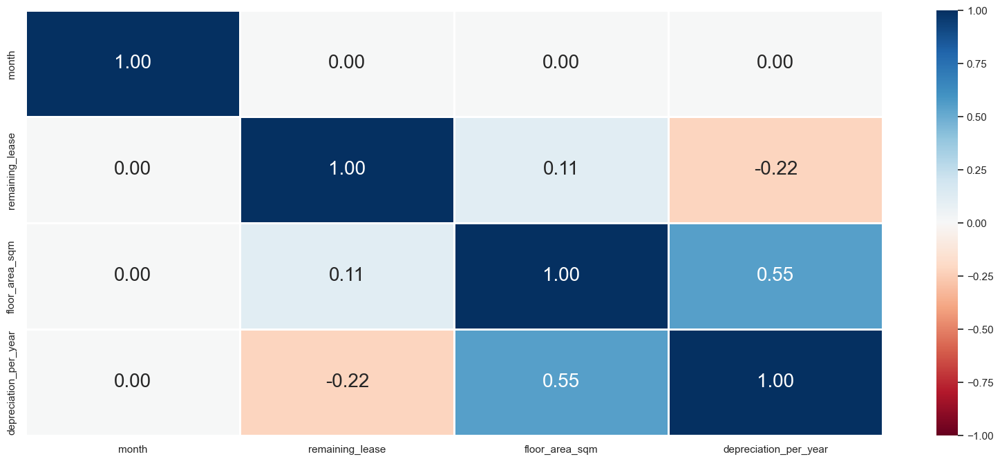

In [63]:
# To find correlation between the numerical variables
# Heatmap of correlation matrix 
plt.figure(figsize=(20, 8))
sb.heatmap(numericalData.corr(), vmin = -1, vmax = 1, linewidths = 1,
           annot = True, fmt = ".2f", annot_kws = {"size": 20}, cmap = "RdBu") #see the dependence of variables on the depreciation per year

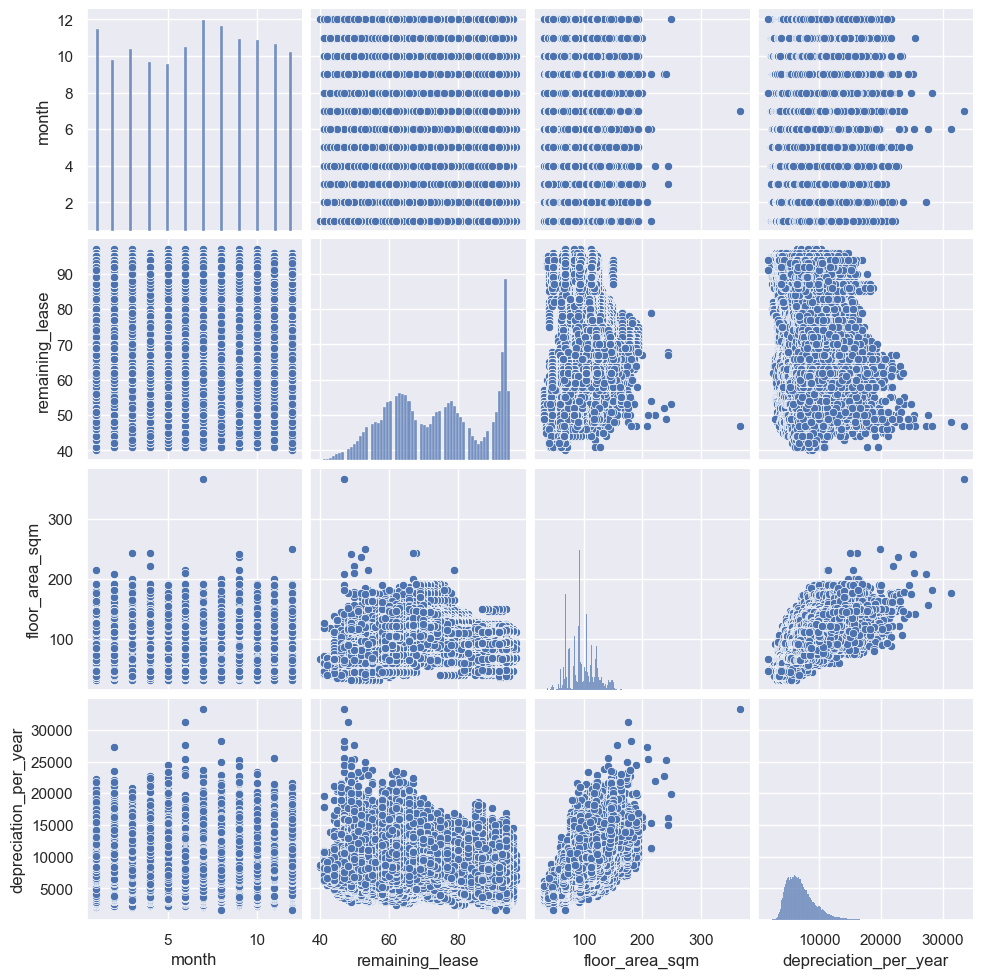

In [64]:
sb.pairplot(data = numericalData) 

#### Observation:
1. Strongest Influence on Depreciation per Year: Floor Area (sqm).


The variable floor_area_sqm has the strongest correlation with depreciation_per_year, with a coefficient of 0.55.
This indicates that larger flats tend to experience higher absolute depreciation per year compared to smaller flats. This might be due to the fact that bigger flats have higher absolute prices, so their depreciation in dollar terms is also higher, even if the percentage loss is similar across different sizes.

2. Weak Negative Correlation Between Remaining Lease and Depreciation per Year (-0.22).


The correlation between remaining_lease and depreciation_per_year is -0.22, which is weakly negative.
This suggests that as the remaining lease decreases, the depreciation per year slightly increases. However, this effect is not very strong. This aligns with the earlier findings that floor area has a stronger influence on price depreciation than lease remaining.

3. Minimal Correlation Between Floor Area and Remaining Lease (0.11).


The correlation between floor_area_sqm and remaining_lease is only 0.11, indicating almost no relationship.
This means that flat size does not strongly depend on lease duration.
This makes sense because different-sized flats (e.g., 3-room vs. 5-room) exist across different lease periods.

**Since floor_area_sqm has the highest correlation with depreciation_per_year, it is the best candidate for our further analysis using linear regression model.**

### 6.1d: Linear Regression Model Depreciation using Floor Area

In [67]:
# Import Linear Regression model from Scikit-Learn
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

In [68]:
# Split the dataset randomly into Train and Test 
X = pd.DataFrame(flat_data['floor_area_sqm'])
y = pd.DataFrame(flat_data['depreciation_per_year'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20)

# Check the sample sizes
print("Train Set :", X_train.shape, y_train.shape)
print("Test Set  :", X_test.shape, y_test.shape)

Train Set : (160565, 1) (160565, 1)
Test Set  : (40142, 1) (40142, 1)


Dataset Splitting & Sample Sizes:

The dataset was split into 80% training data (160,565 samples) and 20% test data (40,412 samples).
Making it reasonable train-test split ratio, ensuring enough data for both training and evaluation.

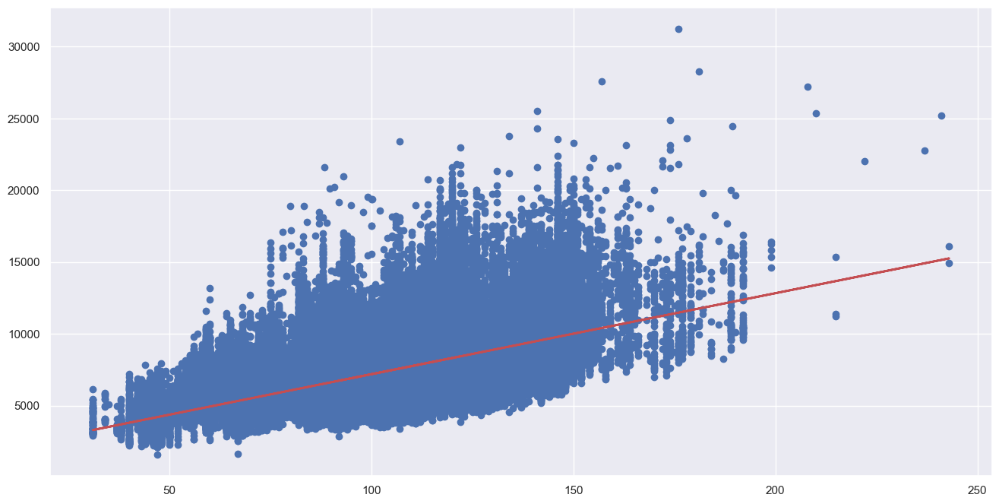

In [70]:
# Create a linear regression object
linreg = LinearRegression() 

# using train set to train model
linreg.fit(X_train, y_train) 

# using test set to test model by obtaining the predicted output via the fitted model with X_test as input
Y_pred = linreg.predict(X_test) 

# Formula for the Regression line
regline_x = X_train
regline_y = linreg.intercept_ + linreg.coef_ * regline_x

# Plot the Linear Regression line
f, axes = plt.subplots(1, 1, figsize=(16, 8))

# Scatter plot for floor_area_sqm_train(x-axis) vs depreciation_per_year_train (y-axis) 
plt.scatter(X_train, y_train) 

# Regression line plot from the fitting above
plt.plot(regline_x, regline_y, 'r-', linewidth = 2)

#### Observations: 
The red regression line shows the fitted linear trend. There is a positive trend, meaning that larger flats generally depreciate at a higher absolute value per year. However, there is a large spread (variance) in depreciation values for similar floor areas. This suggests that while floor area is a key factor, it is not the only factor influencing depreciation. Other variables could contribute.

###  6.1e: Linear Regression Model Depreciation Prediction based on Floor Area

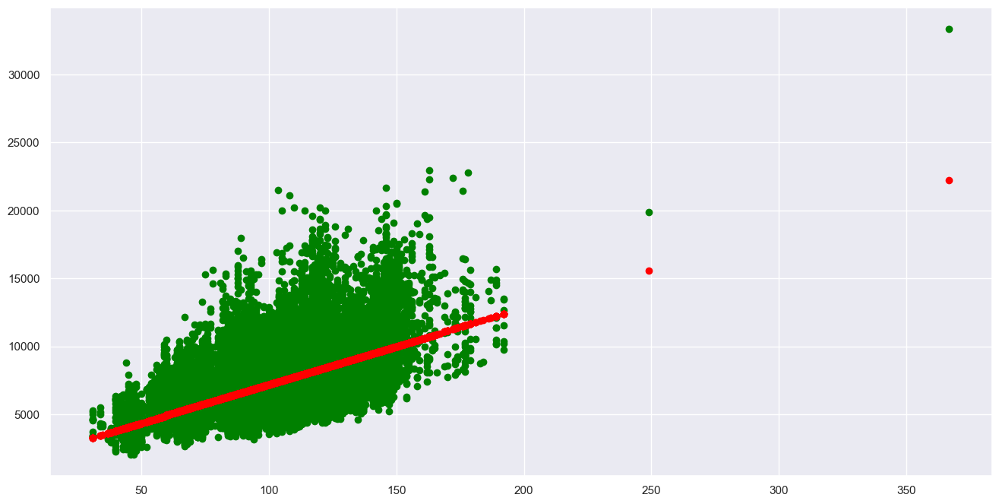

In [73]:
# Predict Depreciation Rate values corresponding to Floor Area
y_test_pred = linreg.predict(X_test)

# Plot the Predictions
plt.figure(figsize=(16, 8))
plt.scatter(X_test, y_test, color = "green")
plt.scatter(X_test, y_test_pred, color = "red")

#### Observations: 
- The green scatter points represent the actual depreciation values in the test set, while the red points represent the model's predictions.
- The red regression line shows a positive correlation between floor area (sqm) and depreciation per year, meaning larger flats tend to have a higher depreciation value.
- However, the model does not fit the data well, as seen by the wide dispersion of green points around the red regression line.

In [75]:
R2_train = linreg.score(X_train,y_train) 
R2_test = linreg.score(X_test,y_test) 
intercept = linreg.intercept_[0]  # Extracts the single element from the array
coefficient = linreg.coef_[0, 0]  # Extracts the single coefficient value properly
print('Intercept of Regression \t\t:', intercept)
print('Coefficients of Regression \t\t:', coefficient)
print('Explained Variance (R^2) on Train Set \t:', R2_train)
print('Explained Variance (R^2) on Test Set \t:', R2_test)

Intercept of Regression 		: 1546.4296592674682
Coefficients of Regression 		: 56.40832135417447
Explained Variance (R^2) on Train Set 	: 0.30882095107590024
Explained Variance (R^2) on Test Set 	: 0.30158021711965066


In [76]:
X_input = [30, 40, 50, 60, 70]  # Sample input floor area
X_input_DF = pd.DataFrame(X_input, columns=['floor_area_sqm'])
Y_pred = linreg.predict(X_input_DF)  # Predict depreciation rates
Y_pred_DF = pd.DataFrame(Y_pred, columns=['Predicted Depreciation Rate (Output)'])
# Combine input and output into one table
combined_Columns = pd.concat([X_input_DF, Y_pred_DF], axis=1)
combined_Columns

,floor_area_sqm,Predicted Depreciation Rate (Output)
0,30,3238.68
1,40,3802.76
2,50,4366.85
3,60,4930.93
4,70,5495.01


#### Observations:

Low R² Scores:
- Since R² is close to 0.3, this means that ~70% of the variance in depreciation remains unexplained by floor area alone.
- Other factors like location, remaining lease, and floor level likely influence depreciation more significantly.

Regression Coefficients Interpretation:
- Intercept: $1568.12$ → This is the baseline depreciation even if the floor area is 0 sqm.
- Coefficient: $56.16$ → This means that for every additional sqm, the depreciation increases by ~$56.16 per year on average.

Predicted Depreciation for Sample Floor Areas:
- A 30 sqm flat is expected to depreciate by $3,252.96$ per year.
A 70 sqm flat is expected to depreciate by $5,499.41$ per year.
The trend is increasing linearly, but the low R² suggests these predictions may not be highly accurate.

Potential Issues with Model Performance:
- Depreciation is likely influenced by more factors than just floor area.
- The spread of data in the scatter plot suggests the model underestimates depreciation for some flats and overestimates for others.
- Outliers in larger floor areas (>200 sqm) may be distorting the regression fit.

###  6.1f: Depreciation Prediction based on Month

## **This part is just further exploration of months, since it showed 0 information in the above explorations. Since depreciation is a long-term trend, looking at month-to-month changes might not be very meaningful.**

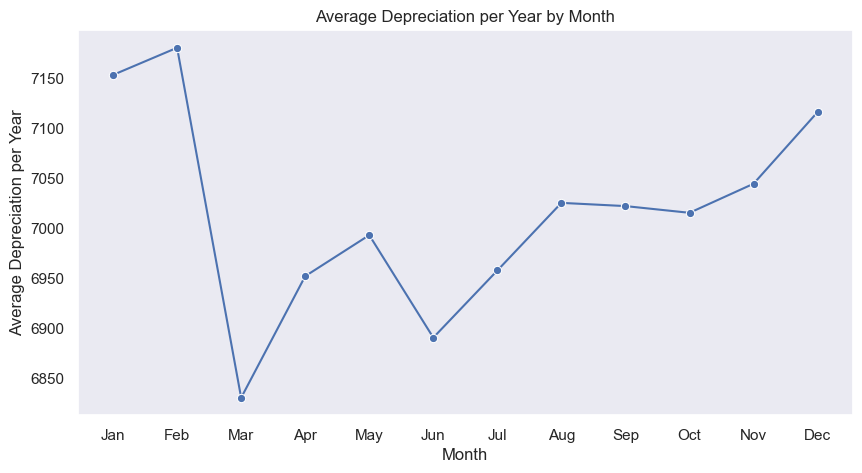

In [79]:
plt.figure(figsize=(10, 5))
sb.lineplot(x='month', y='depreciation_per_year', data=monthly_avg_depreciation, marker='o')
plt.xticks(ticks=range(1, 13), labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 
                                       'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.xlabel('Month')
plt.ylabel('Average Depreciation per Year')
plt.title('Average Depreciation per Year by Month')
plt.grid()
plt.show()

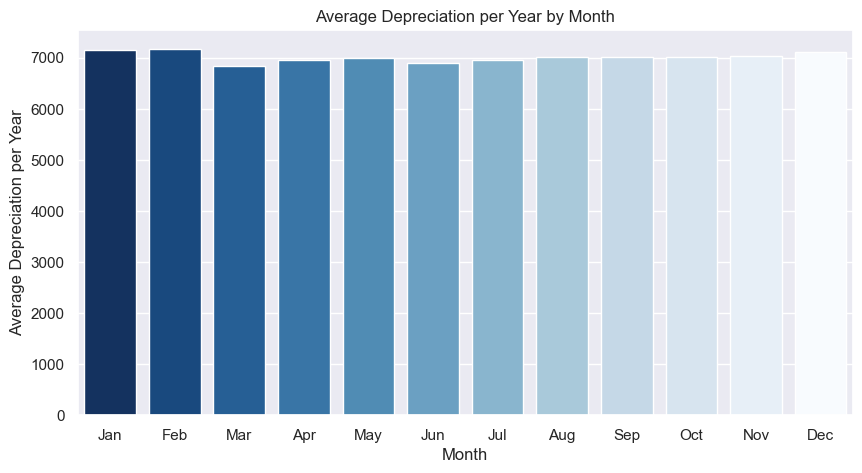

In [80]:
plt.figure(figsize=(10, 5))

sb.barplot(x='month', y='depreciation_per_year', hue='month', data=monthly_avg_depreciation, palette='Blues_r', legend=False)

plt.xticks(ticks=range(12), labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 
                                    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.xlabel('Month')
plt.ylabel('Average Depreciation per Year')
plt.title('Average Depreciation per Year by Month')
plt.show()

## 6.2: Categorical Data

### 6.2a: Summary Statistics of Categorical Data

In [83]:
# Categorical Data
categoricaldata = pd.DataFrame(flat_data[["town","flat_type","storey_range","flat_model"]])
categoricalData = categoricaldata.astype('category')
categoricalData.head()

,town,flat_type,storey_range,flat_model
0,ANG MO KIO,2 ROOM,10 TO 12,Improved
1,ANG MO KIO,3 ROOM,01 TO 03,New Generation
2,ANG MO KIO,3 ROOM,01 TO 03,New Generation
3,ANG MO KIO,3 ROOM,04 TO 06,New Generation
4,ANG MO KIO,3 ROOM,01 TO 03,New Generation


In [84]:
categoricalData.describe()

,town,flat_type,storey_range,flat_model
count,200707,200707,200707,200707
unique,26,7,17,21
top,SENGKANG,4 ROOM,04 TO 06,Model A
freq,16525,84738,46122,70773


#### Observations:

1. Town Distribution (town)
- Most frequent town: Sengkang (16,525 transactions)

2. Flat Type Distribution (flat_type)
- Most common flat type: 4 ROOM (84,738 transactions)
     
3. Storey Range (storey_range)
- Most common storey range: "04 TO 06" (46,122 transactions)

4. Flat Model (flat_model)
- Most common model: "Model A" (70,773 transactions)

In [86]:
CatData = pd.concat([categoricalData, DepreciationRate], axis = 1) 
CatData.head()

,town,flat_type,storey_range,flat_model,depreciation_per_year
0,ANG MO KIO,2 ROOM,10 TO 12,Improved,3803.28
1,ANG MO KIO,3 ROOM,01 TO 03,New Generation,4166.67
2,ANG MO KIO,3 ROOM,01 TO 03,New Generation,4225.81
3,ANG MO KIO,3 ROOM,04 TO 06,New Generation,4274.19
4,ANG MO KIO,3 ROOM,01 TO 03,New Generation,4274.19


### 6.2b: Relationship between Town and Depreciation Price

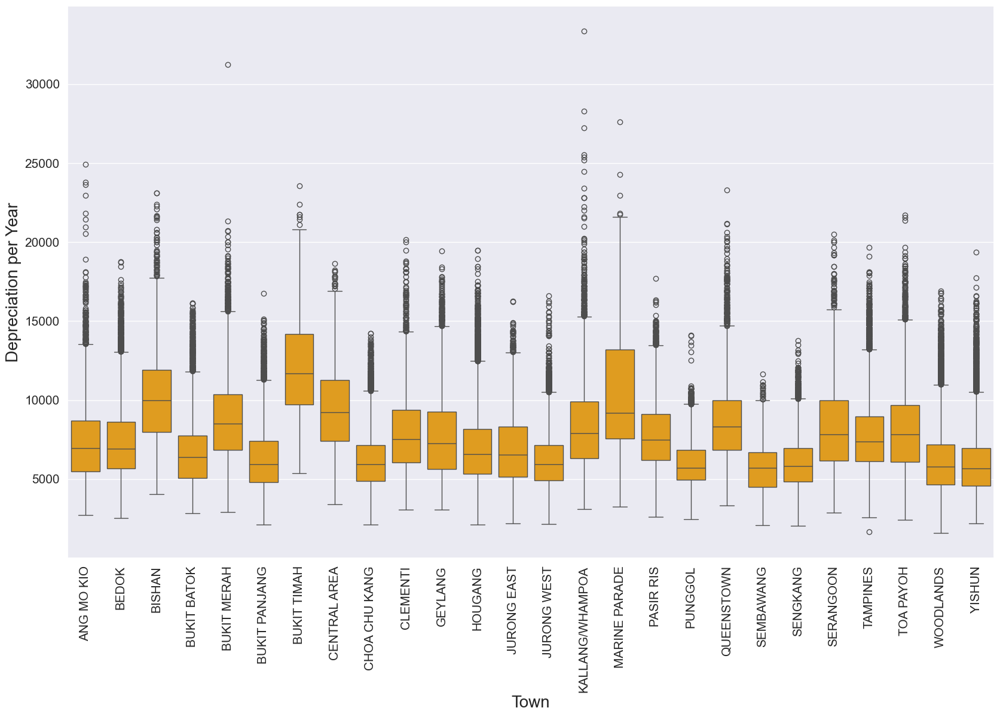

In [88]:
f, axes = plt.subplots(1, 1, figsize=(20, 12))
sb.boxplot(x = 'town', y = 'depreciation_per_year', data = CatData, color = 'orange')

plt.xlabel("Town", fontsize=20)  # Set x-axis title font size
plt.ylabel("Depreciation per Year", fontsize=20)  # Set y-axis title font size

plt.xticks(rotation = 90)
plt.xticks(fontsize = 15);
plt.yticks(fontsize = 15);

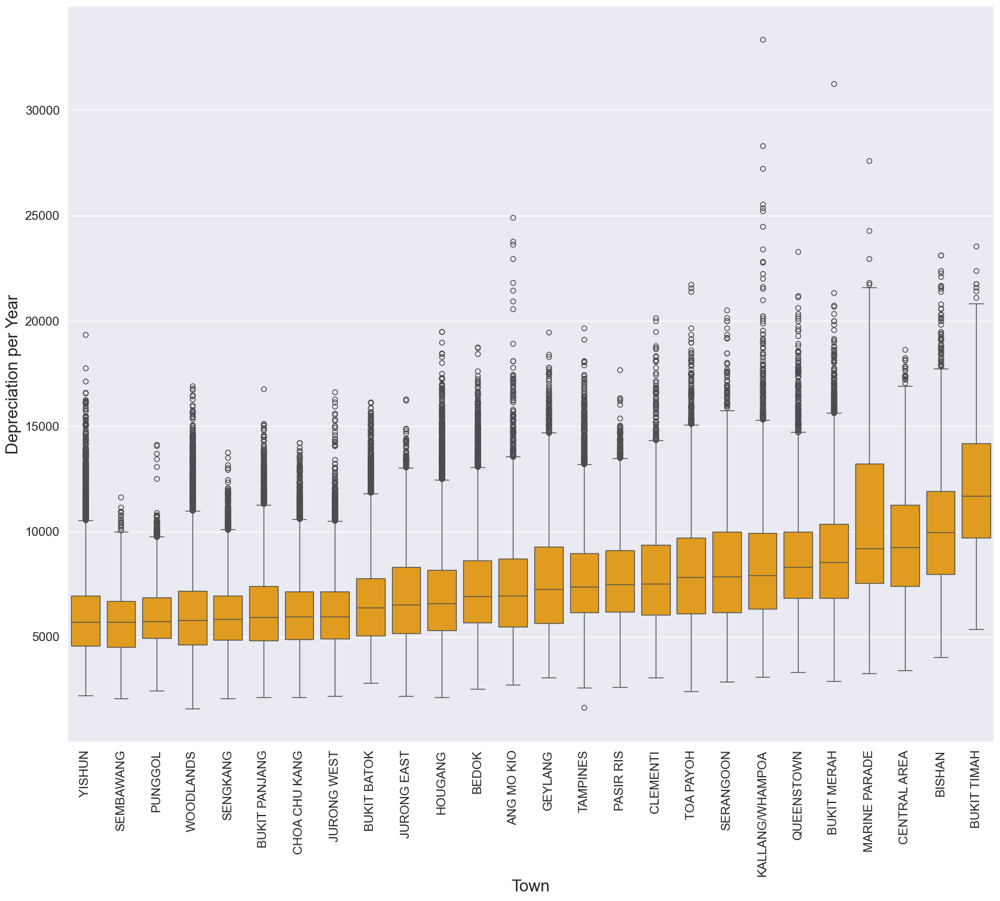

In [89]:
# Rearrange the Town data in increasing trend of median values
new_town = CatData.loc[:,['town', 'depreciation_per_year']] \
    .groupby(['town'], observed=True).median() \
    .sort_values(by = 'depreciation_per_year')
f = plt.subplots(figsize=(20,16))


plt.xlabel("Town", fontsize=20)  # Set x-axis title font size
plt.ylabel("Depreciation per Year", fontsize=20)  # Set y-axis title font size

sb.boxplot(x = 'town', y ='depreciation_per_year', data = CatData, order = new_town.index, color="Orange")
plt.xticks(rotation = 90);
plt.xticks(fontsize = 15);
plt.yticks(fontsize = 15);

#### Observation: 
- Different towns show significant variations in median depreciation per year.
- Certain towns have higher depreciation, possibly due to factors like demand, location, or lease decay effects.
- Towns with higher resale prices tend to show greater absolute depreciation per year.
- Outliers are present across towns, indicating that some flats experience extreme depreciation.

### 6.2c: Relationship between Flat Type and Depreciation Price

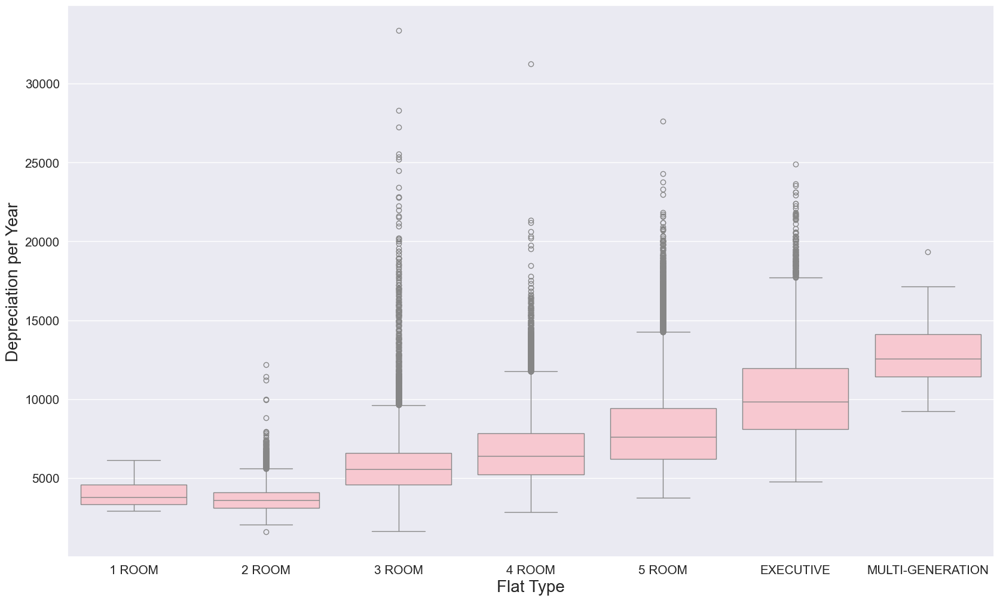

In [92]:
f, axes = plt.subplots(1, 1, figsize=(20, 12))

plt.xlabel("Flat Type", fontsize=20)  # Set x-axis title font size
plt.ylabel("Depreciation per Year", fontsize=20)  # Set y-axis title font size

sb.boxplot(x = 'flat_type', y = 'depreciation_per_year', data = CatData, color = 'Pink')
plt.xticks(fontsize = 15);
plt.yticks(fontsize = 15);

#### Observation: 
- Larger flats (5-room, Executive, Multi-Generation) tend to have higher depreciation per year than smaller flats (1-room, 2-room).
- The spread of depreciation values increases with flat size, indicating more variability in larger flats.
- There are many outliers in all categories, but they are more extreme in 3-room and larger flats.

### 6.2d: Relationship between Storey Range and Depreciation Price

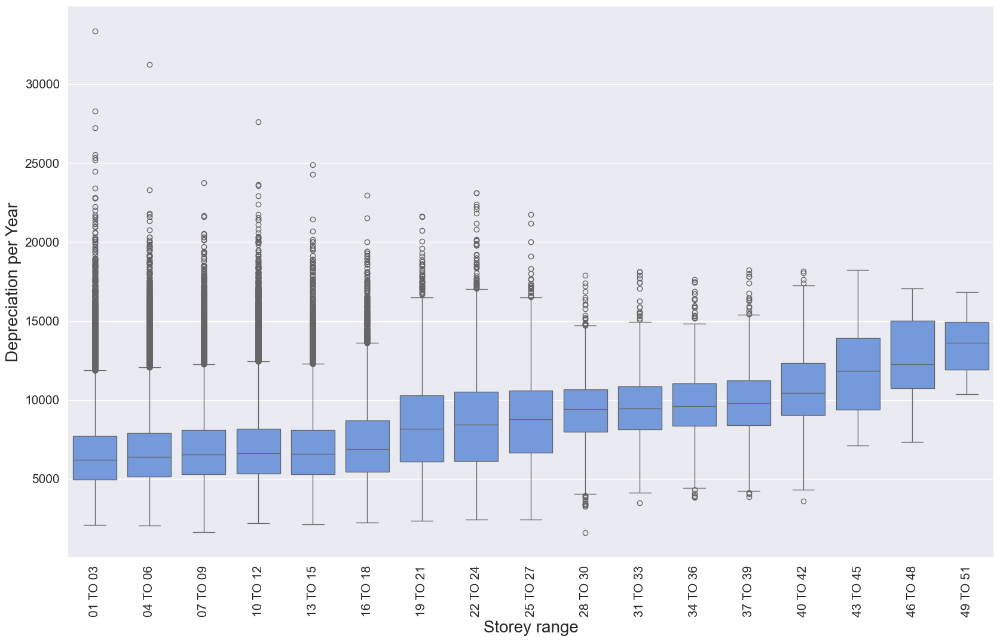

In [95]:
f, axes = plt.subplots(1, 1, figsize=(20,12))

plt.xlabel("Storey range", fontsize=20)  # Set x-axis title font size
plt.ylabel("Depreciation per Year", fontsize=20)  # Set y-axis title font size

sb.boxplot(x = 'storey_range', y = 'depreciation_per_year', data = CatData, color = 'CornFlowerBlue')
plt.xticks(rotation = 90);
plt.xticks(fontsize = 15);
plt.yticks(fontsize = 15);

#### Observation: 
- Higher floors tend to have higher depreciation per year.
- Flats on lower floors (1-3, 4-6, etc.) generally have lower depreciation.
- Flats on higher floors (37-39 and above) show significantly higher depreciation per year.
- The variability increases as the storey range increases, with higher floors having a wider spread of depreciation values.

### 6.2e: Relationship between Flat Model and Depreciation Price

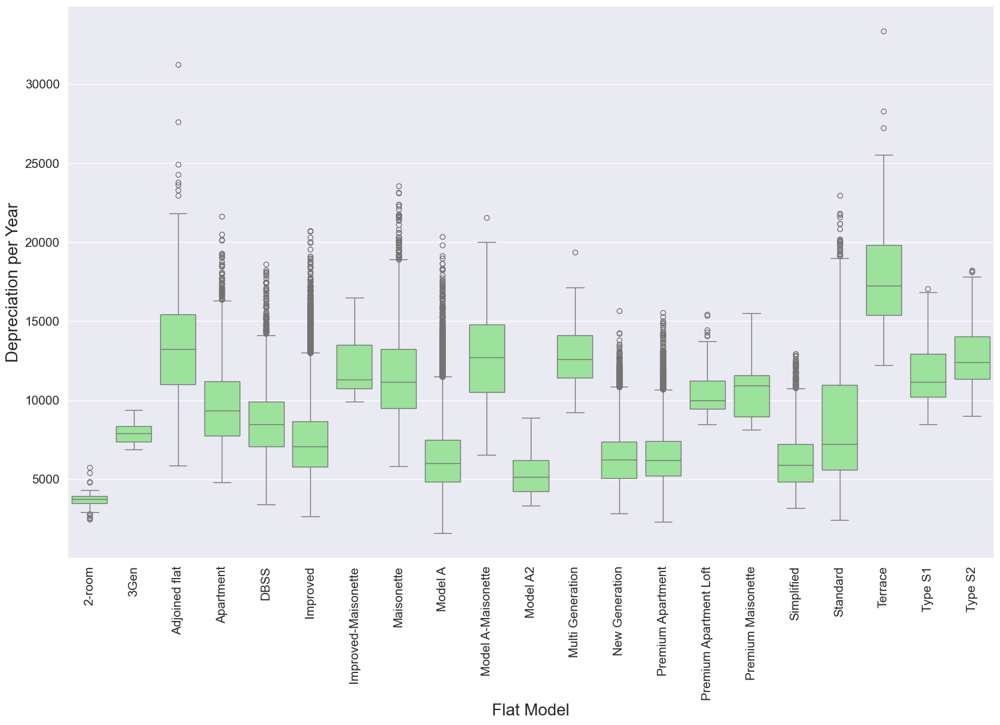

In [98]:
f, axes = plt.subplots(1, 1, figsize=(20, 12))

plt.xlabel("Flat Model", fontsize=20)  # Set x-axis title font size
plt.ylabel("Depreciation per Year", fontsize=20)  # Set y-axis title font size

sb.boxplot(x = 'flat_model', y = 'depreciation_per_year', data = CatData, color = 'lightgreen')
plt.xticks(rotation = 90)
plt.xticks(fontsize = 15);
plt.yticks(fontsize = 15);

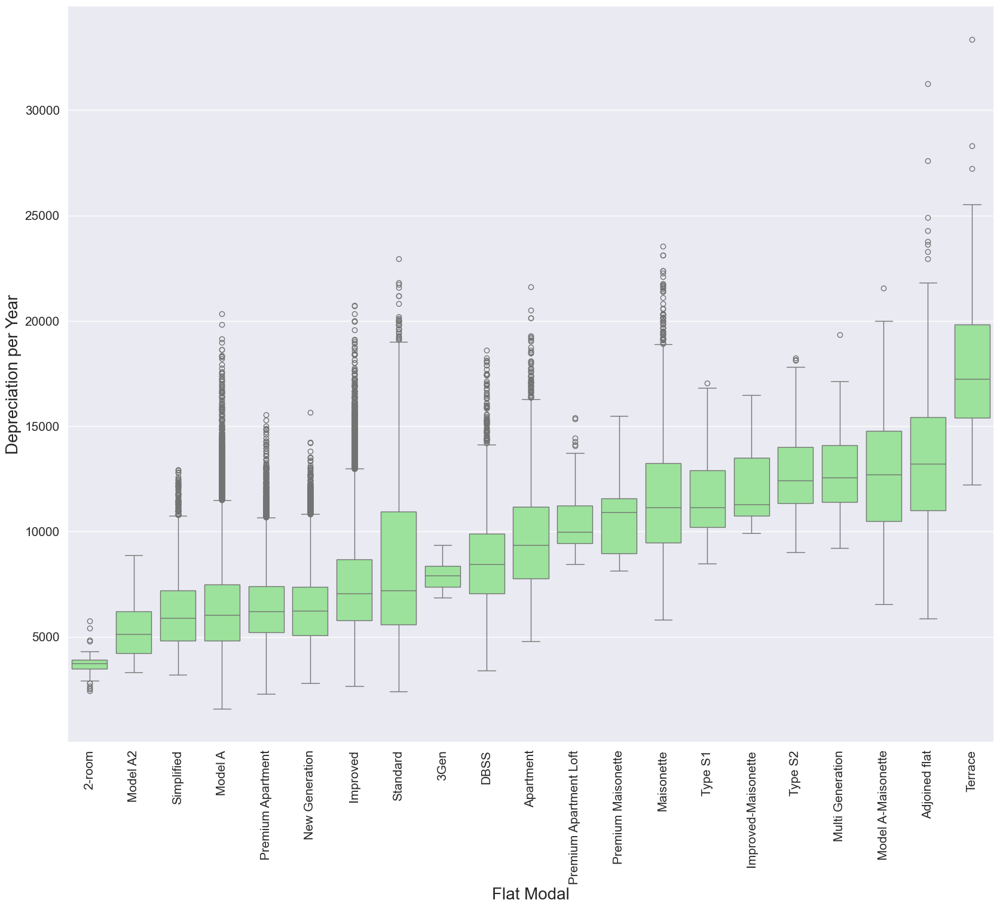

In [99]:
# Rearrange the flat model data in increasing trend of median values
new_flat_model = CatData.loc[:,['flat_model', 'depreciation_per_year']] \
    .groupby(['flat_model'], observed=True).median() \
    .sort_values(by = 'depreciation_per_year')

f=plt.subplots(figsize=(20,16))

plt.xlabel("Flat Modal", fontsize=20)  # Set x-axis title font size
plt.ylabel("Depreciation per Year", fontsize=20)  # Set y-axis title font size

sb.boxplot(x ='flat_model', y ='depreciation_per_year', data = CatData, order = new_flat_model.index, color = "lightgreen")
plt.xticks(rotation = 90);
plt.xticks(fontsize = 15);
plt.yticks(fontsize = 15);

#### Observation:
- Huge differences in depreciation per year across different flat models.
- Terrace flats, Adjoined flats, and Type S2 have the highest depreciation rates.
- 2-room, Model A2, and Simplified flats have the lowest depreciation per year.
- Premium flats (e.g., Maisonettes, Premium Apartments, Loft units) also tend to have high depreciation.
- Reordering by median depreciation (last plot) shows a clear increasing trend.

#### Observations:
Town, Flat Type, Storey Range, and Flat Model significantly impact depreciation per year, as seen in the high variations across their levels. Given the presence of numerous outliers, the median depreciation per year is a more reliable metric for estimating depreciation trends, rather than the mean. This method helps to reduce the influence of extreme values while preserving the overall pattern in depreciation.

# 7: Final Analysis of Model

#### Based on the analysis of numerical and categorical data shown in Parts 6.1 and 6.2. The variations of each variable are listed. The variables that show high variations across the levels are then used to predict resale flat depreciation per year in Singapore.

| Variable            | Variation               |    
| -------------------:| :---------------------: |        
| town                | High                    |
| flat_type           | High                    |   
| storey_range        | High                    |   
| floor_area_sqm      | High                    |   
| flat_model          | High                    |        
| remaining_lease     | Low                     |  

- Town, Flat Type, Storey Range, Floor Area (sqm), and Flat Model all exhibit high variation in depreciation per year, making them important predictors.
- Remaining Lease shows low variation, meaning it has a weaker correlation with annual depreciation, aligning with previous numerical correlation findings.
- Boxplots confirm that higher floor levels, premium flat models, and larger flats tend to depreciate more per year.

In [104]:
#Import Regression model from Scikit-Learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor

In [105]:
# Data used for prediction of depreciation per year
finalData = pd.concat([categoricalData,numericalData],axis = 1)
finalData = finalData.drop(['remaining_lease'],axis = 1)
finalData.head()

,town,flat_type,storey_range,flat_model,month,floor_area_sqm,depreciation_per_year
0,ANG MO KIO,2 ROOM,10 TO 12,Improved,1,44.00,3803.28
1,ANG MO KIO,3 ROOM,01 TO 03,New Generation,1,67.00,4166.67
2,ANG MO KIO,3 ROOM,01 TO 03,New Generation,1,67.00,4225.81
3,ANG MO KIO,3 ROOM,04 TO 06,New Generation,1,68.00,4274.19
4,ANG MO KIO,3 ROOM,01 TO 03,New Generation,1,67.00,4274.19


In [106]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

finalData['town_le'] = le.fit_transform(finalData['town'])
finalData['flat_type_le'] = le.fit_transform(finalData['flat_type'])
finalData['storey_range_le'] = le.fit_transform(finalData['storey_range'])
finalData['flat_model_le'] = le.fit_transform(finalData['flat_model'])

before_after_finalData = finalData.copy()

finalData = finalData[['town_le', 'flat_type_le', 'storey_range_le', 'flat_model_le', 'floor_area_sqm', 'depreciation_per_year']].copy()

finalData.columns = finalData.columns.str.replace('_le', '')

## 7.1: Multi-Variate Regression

In [108]:
finalData.dtypes

town                       int64
flat_type                  int64
storey_range               int64
flat_model                 int64
floor_area_sqm           float64
depreciation_per_year    float64
dtype: object

In [109]:
predictor = pd.DataFrame(finalData[['town','flat_type','storey_range','flat_model', 'floor_area_sqm']])
DepreciationRate = pd.DataFrame(finalData['depreciation_per_year'])

## 7.2: Regression Models on Depreciation Price vs Predictor

In [111]:
# Split the dataset randomly into Train and Test 
predictor_train, predictor_test, DepreciationRate_train, DepreciationRate_test = train_test_split(predictor, DepreciationRate, test_size = 0.20, random_state = 42)

# Check the sample sizes
print("Train Set :", predictor_train.shape, DepreciationRate_train.shape)
print("Test Set  :", predictor_test.shape, DepreciationRate_test.shape)

# Create a Linear Regression object
linreg1 = LinearRegression()
linreg2 = GradientBoostingRegressor()
linreg3 = RandomForestRegressor()

# Train the Linear Regression model
linreg1.fit(predictor_train, DepreciationRate_train.values.ravel())
linreg2.fit(predictor_train, DepreciationRate_train.values.ravel())
linreg3.fit(predictor_train, DepreciationRate_train.values.ravel())

Train Set : (160565, 5) (160565, 1)
Test Set  : (40142, 5) (40142, 1)


RandomForestRegressor()

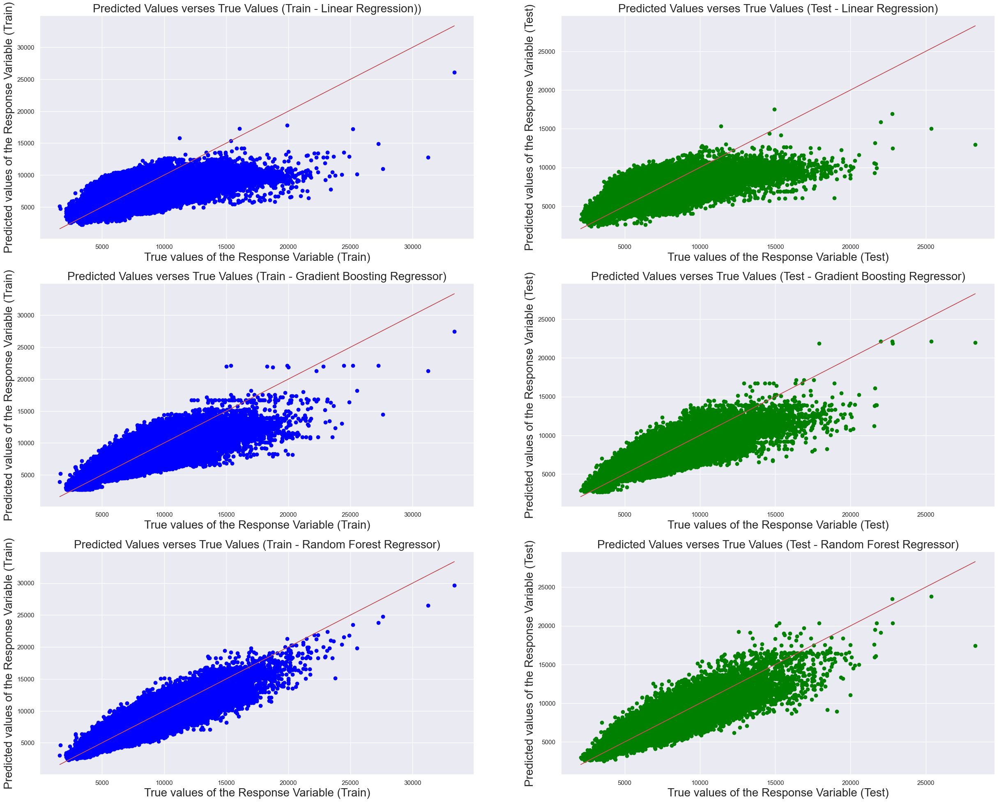

In [112]:
# [Linear Regression] Depreciation Per Year values corresponding to the variables
lr_DepreciationRate_train_pred = linreg1.predict(predictor_train)
lr_DepreciationRate_test_pred = linreg1.predict(predictor_test)

# [Gradient Boosting Model] Depreciation Per Year values corresponding to the variables
gb_DepreciationRate_train_pred = linreg2.predict(predictor_train)
gb_DepreciationRate_test_pred = linreg2.predict(predictor_test)

# [Random Forest Regressor Model] Depreciation Per Year values corresponding to the variables
rf_DepreciationRate_train_pred = linreg3.predict(predictor_train)
rf_DepreciationRate_test_pred = linreg3.predict(predictor_test)

# Plot the Predictions vs the True values
f, axes = plt.subplots(3, 2, figsize=(30, 24))

axes[0, 0].scatter(DepreciationRate_train, lr_DepreciationRate_train_pred, color="blue")
axes[0, 0].plot(DepreciationRate_train, DepreciationRate_train, 'r-', linewidth=1)
axes[0, 0].set_title("Predicted Values verses True Values (Train - Linear Regression))", fontsize=20)
axes[0, 0].set_xlabel("True values of the Response Variable (Train)", fontsize=20)
axes[0, 0].set_ylabel("Predicted values of the Response Variable (Train)", fontsize=20)

axes[0, 1].scatter(DepreciationRate_test, lr_DepreciationRate_test_pred, color = "green")
axes[0, 1].plot(DepreciationRate_test, DepreciationRate_test, 'r-', linewidth = 1)
axes[0, 1].set_title("Predicted Values verses True Values (Test - Linear Regression)", fontsize=20)
axes[0, 1].set_xlabel("True values of the Response Variable (Test)", fontsize=20)
axes[0, 1].set_ylabel("Predicted values of the Response Variable (Test)", fontsize=20)

# Plot the Predictions vs the True values
axes[1,0].scatter(DepreciationRate_train, gb_DepreciationRate_train_pred, color = "blue")
axes[1,0].plot(DepreciationRate_train, DepreciationRate_train, 'r-', linewidth = 1)
axes[1,0].set_title("Predicted Values verses True Values (Train - Gradient Boosting Regressor)", fontsize=20)
axes[1,0].set_xlabel("True values of the Response Variable (Train)", fontsize=20)
axes[1,0].set_ylabel("Predicted values of the Response Variable (Train)", fontsize=20)

axes[1,1].scatter(DepreciationRate_test, gb_DepreciationRate_test_pred, color = "green")
axes[1,1].plot(DepreciationRate_test, DepreciationRate_test, 'r-', linewidth = 1)
axes[1,1].set_title("Predicted Values verses True Values (Test - Gradient Boosting Regressor)", fontsize=20)
axes[1,1].set_xlabel("True values of the Response Variable (Test)", fontsize=20)
axes[1,1].set_ylabel("Predicted values of the Response Variable (Test)", fontsize=20)

# Plot the Predictions vs the True values
axes[2,0].scatter(DepreciationRate_train, rf_DepreciationRate_train_pred, color = "blue")
axes[2,0].plot(DepreciationRate_train, DepreciationRate_train, 'r-', linewidth = 1)
axes[2,0].set_title("Predicted Values verses True Values (Train - Random Forest Regressor)", fontsize=20)
axes[2,0].set_xlabel("True values of the Response Variable (Train)", fontsize=20)
axes[2,0].set_ylabel("Predicted values of the Response Variable (Train)", fontsize=20)

axes[2,1].scatter(DepreciationRate_test, rf_DepreciationRate_test_pred, color = "green")
axes[2,1].plot(DepreciationRate_test, DepreciationRate_test, 'r-', linewidth = 1)
axes[2,1].set_title("Predicted Values verses True Values (Test - Random Forest Regressor)", fontsize=20)
axes[2,1].set_xlabel("True values of the Response Variable (Test)", fontsize=20)
axes[2,1].set_ylabel("Predicted values of the Response Variable (Test)", fontsize=20)
plt.show()

In [113]:
# Goodness of Fit of Linear Regression Model
R2_train_linear = linreg1.score(predictor_train, DepreciationRate_train)
R2_test_linear = linreg1.score(predictor_test, DepreciationRate_test)
print("Explained Variance (R^2) on Train Set \t:", R2_train_linear)
print("Explained Variance (R^2) on Test Set \t:", R2_test_linear)

lr_R2 = pd.DataFrame(data = {'Model': ['Linear Regression'], 'R2 (Train)': [R2_train_linear], 'R2 (Test)': [R2_test_linear]})

Explained Variance (R^2) on Train Set 	: 0.3767023364050014
Explained Variance (R^2) on Test Set 	: 0.38294788463941476


In [114]:
lr_R2

,Model,R2 (Train),R2 (Test)
0,Linear Regression,0.38,0.38


In [115]:
# Goodness of Fit of GradientBoosting Regression Model
R2_train_linear = linreg2.score(predictor_train, DepreciationRate_train)
R2_test_linear = linreg2.score(predictor_test, DepreciationRate_test)
print("Explained Variance (R^2) on Train Set \t:", R2_train_linear)
print("Explained Variance (R^2) on Test Set \t:", R2_test_linear)

gb_R2 = pd.DataFrame(data = {'Model': ['Gradient Boosting Regressor'], 'R2 (Train)': [R2_train_linear], 'R2 (Test)': [R2_test_linear]})

Explained Variance (R^2) on Train Set 	: 0.6360127494466215
Explained Variance (R^2) on Test Set 	: 0.6362565388453967


In [116]:
gb_R2

,Model,R2 (Train),R2 (Test)
0,Gradient Boosting Regressor,0.64,0.64


In [117]:
# Goodness of Fit of RandomForest Regression Model
R2_train_linear = linreg3.score(predictor_train, DepreciationRate_train)
R2_test_linear = linreg3.score(predictor_test, DepreciationRate_test)
print("Explained Variance (R^2) on Train Set \t:", R2_train_linear)
print("Explained Variance (R^2) on Test Set \t:", R2_test_linear)

rf_R2 = pd.DataFrame(data = {'Model': ['Random Forest Regressor'], 'R2 (Train)': [R2_train_linear], 'R2 (Test)': [R2_test_linear]})

Explained Variance (R^2) on Train Set 	: 0.7559131086106207
Explained Variance (R^2) on Test Set 	: 0.7041763450068643


In [118]:
rf_R2

,Model,R2 (Train),R2 (Test)
0,Random Forest Regressor,0.76,0.70


In [119]:
final_R2 = pd.concat([lr_R2, gb_R2, rf_R2]).reset_index(drop = True)

In [120]:
final_R2

,Model,R2 (Train),R2 (Test)
0,Linear Regression,0.38,0.38
1,Gradient Boosting Regressor,0.64,0.64
2,Random Forest Regressor,0.76,0.70


# 8: Mathematical Model

In [122]:
# Arrange town data alphabetically in ascending order
Town = before_after_finalData[['town','town_le']].copy()
Town.drop_duplicates(subset=['town'], inplace = True)    
Town.sort_values('town', inplace = True)
Town.reset_index(drop = True, inplace = True)
Town.head()

,town,town_le
0,ANG MO KIO,0
1,BEDOK,1
2,BISHAN,2
3,BUKIT BATOK,3
4,BUKIT MERAH,4


In [123]:
# Arrange Flat Type data in ascending order
FlatType = before_after_finalData[['flat_type','flat_type_le']].copy()
FlatType.drop_duplicates(subset=['flat_type'], inplace = True)    
FlatType.sort_values('flat_type', inplace = True)
FlatType.reset_index(drop = True, inplace = True)
FlatType.head()

,flat_type,flat_type_le
0,1 ROOM,0
1,2 ROOM,1
2,3 ROOM,2
3,4 ROOM,3
4,5 ROOM,4


In [124]:
# Arrange Storey Range data in ascending order
StoreyRange = before_after_finalData[['storey_range','storey_range_le']].copy()
StoreyRange.drop_duplicates(subset=['storey_range'], inplace = True)    
StoreyRange.sort_values('storey_range', inplace = True)
StoreyRange.reset_index(drop = True, inplace = True)
StoreyRange.head()

,storey_range,storey_range_le
0,01 TO 03,0
1,04 TO 06,1
2,07 TO 09,2
3,10 TO 12,3
4,13 TO 15,4


In [125]:
# Arrange Flat Model data in ascending order
FlatModel = before_after_finalData[['flat_model','flat_model_le']].copy()
FlatModel.drop_duplicates(subset=['flat_model'], inplace = True)    
FlatModel.sort_values('flat_model', inplace = True)
FlatModel.reset_index(drop = True, inplace = True)
FlatModel.head()

,flat_model,flat_model_le
0,2-room,0
1,3Gen,1
2,Adjoined flat,2
3,Apartment,3
4,DBSS,4


In [182]:
def show_pricing_model():
    # Get user inputs
    print("INPUTS ARE CASE SENSITIVE, PLEASE FOLLOW AND MATCH ACCORDINGLY")
    town = input(f"Enter Town ({', '.join(sorted(list(Town['town'].unique())))}): ")
    flat_type = input(f"Enter Flat Type ({', '.join(sorted(list(FlatType['flat_type'].unique())))}): ")
    storey_range = input(f"Enter Storey Range ({', '.join(sorted(list(StoreyRange['storey_range'].unique())))}): ")
    flat_model = input(f"Enter Flat Model ({', '.join(sorted(list(FlatModel['flat_model'].unique())))}): ")

    while True:
        try:
            floor_area_sqm = float(input("Enter Floor Area (sqm) [0 - 1000]: "))
            if 0 <= floor_area_sqm <= 1000:
                break
            else:
                print("Invalid input! Floor Area must be between 0 and 1000.")
        except ValueError:
            print("Invalid input! Please enter a numerical value.")

    while True:
        try:
            years_from_now = int(input("Enter Years from Now to Predict Depreciation: "))
            if years_from_now >= 0:
                break
            else:
                print("Invalid input! Years from Now must be non-negative.")
        except ValueError:
            print("Invalid input! Please enter an integer value.")

    # 1st Try: Match All User Inputs
    matching_flats = flat_data[
        (flat_data["town"] == town) &
        (flat_data["flat_type"] == flat_type) &
        (flat_data["storey_range"] == storey_range) &
        (flat_data["flat_model"] == flat_model)
    ]

    # 2nd Try: If No Match, Loosen Criteria (Ignore Storey)
    if matching_flats.empty:
        matching_flats = flat_data[
            (flat_data["town"] == town) &
            (flat_data["flat_type"] == flat_type) &
            (flat_data["flat_model"] == flat_model)
        ]

    # 3rd Try: If Still No Match, Use Overall Average
    if matching_flats.empty:
        print("\nNo close match found! Using dataset-wide average depreciation.")
        avg_depreciation = flat_data["depreciation_per_year"].mean()
        estimated_resale_price = flat_data["resale_price"].mean()
    else:
        avg_depreciation = matching_flats["depreciation_per_year"].mean()
        estimated_resale_price = matching_flats["resale_price"].mean()

    # Calculate total depreciation and future value
    total_depreciation = avg_depreciation * years_from_now
    future_value = estimated_resale_price - total_depreciation

    # Display results
    print(f"\n### Predicted Depreciation ###")
    print(f"Town: {town}")
    print(f"Flat Type: {flat_type}")
    print(f"Storey Range: {storey_range}")
    print(f"Flat Model: {flat_model}")
    print(f"Floor Area (sqm): {floor_area_sqm}")
    print(f"Years From Now: {years_from_now}")
    print(f"Avg Depreciation Per Year: SGD {avg_depreciation:,.2f}")
    print(f"Total Depreciation: SGD {total_depreciation:,.2f}")
    print(f"Predicted Future Value: SGD {future_value:,.2f}")

    return future_value

# Call the function
show_pricing_model()

INPUTS ARE CASE SENSITIVE, PLEASE FOLLOW AND MATCH ACCORDINGLY


Enter Town (ANG MO KIO, BEDOK, BISHAN, BUKIT BATOK, BUKIT MERAH, BUKIT PANJANG, BUKIT TIMAH, CENTRAL AREA, CHOA CHU KANG, CLEMENTI, GEYLANG, HOUGANG, JURONG EAST, JURONG WEST, KALLANG/WHAMPOA, MARINE PARADE, PASIR RIS, PUNGGOL, QUEENSTOWN, SEMBAWANG, SENGKANG, SERANGOON, TAMPINES, TOA PAYOH, WOODLANDS, YISHUN):  ANG MO KIO
Enter Flat Type (1 ROOM, 2 ROOM, 3 ROOM, 4 ROOM, 5 ROOM, EXECUTIVE, MULTI-GENERATION):  3 ROOM
Enter Storey Range (01 TO 03, 04 TO 06, 07 TO 09, 10 TO 12, 13 TO 15, 16 TO 18, 19 TO 21, 22 TO 24, 25 TO 27, 28 TO 30, 31 TO 33, 34 TO 36, 37 TO 39, 40 TO 42, 43 TO 45, 46 TO 48, 49 TO 51):  10 TO 12
Enter Flat Model (2-room, 3Gen, Adjoined flat, Apartment, DBSS, Improved, Improved-Maisonette, Maisonette, Model A, Model A-Maisonette, Model A2, Multi Generation, New Generation, Premium Apartment, Premium Apartment Loft, Premium Maisonette, Simplified, Standard, Terrace, Type S1, Type S2):  New Generation
Enter Floor Area (sqm) [0 - 1000]:  67
Enter Years from Now to Predict


### Predicted Depreciation ###
Town: ANG MO KIO
Flat Type: 3 ROOM
Storey Range: 10 TO 12
Flat Model: New Generation
Floor Area (sqm): 67.0
Years From Now: 2
Avg Depreciation Per Year: SGD 6,124.10
Total Depreciation: SGD 12,248.21
Predicted Future Value: SGD 335,655.02


335655.0165715722